
# data loading (DeepPCB dataset)

##### This part reads the DeepPCB train and test files. For each sample it loads
##### the test image, its defect-free template, and the open/short boxes. The other
##### parts use them for the detection and the evaluation.

In [1]:

import os

if not os.path.exists("DeepPCB"):
    !git clone https://github.com/tangsanli5201/DeepPCB.git

Cloning into 'DeepPCB'...
remote: Enumerating objects: 4753, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4753 (delta 13), reused 12 (delta 12), pack-reused 4739 (from 1)
Receiving objects: 100% (4753/4753), 85.81 MiB | 25.73 MiB/s, done.
Resolving deltas: 100% (191/191), done.
Updating files: 100% (4548/4548), done.


In [2]:
import os
import cv2
from collections import Counter

# path to the dataset folder
ROOT = "DeepPCB/PCBData"

# defect type numbers from the annotation files
NAMES = {1: "open", 2: "short", 3: "mousebite", 4: "spur", 5: "copper", 6: "pin-hole"}
# only open and short for our project
KEEP = {1, 2}


# reads trainval.txt or test.txt
def list_samples(split="train"):
    fname = "trainval.txt" if split == "train" else "test.txt"
    samples = []
    with open(os.path.join(ROOT, fname)) as f:
        for line in f:
            parts = line.replace(",", " ").split()
            if len(parts) >= 2:
                samples.append((parts[0].replace(".jpg", ""), parts[1]))
    return samples


# returns test image, template, and the boxes (x1, y1, x2, y2, type)
def load_pair(sample):
    img_path, ann_path = sample
    test = cv2.imread(os.path.join(ROOT, img_path + "_test.jpg"), cv2.IMREAD_GRAYSCALE)
    temp = cv2.imread(os.path.join(ROOT, img_path + "_temp.jpg"), cv2.IMREAD_GRAYSCALE)

    boxes = []
    with open(os.path.join(ROOT, ann_path)) as f:
        for line in f:
            p = line.replace(",", " ").split()
            if len(p) == 5 and int(p[4]) in KEEP:
                boxes.append((int(p[0]), int(p[1]), int(p[2]), int(p[3]), int(p[4])))
    return test, temp, boxes


# number of defects per type
def stats(split="train"):
    counter = Counter()
    for s in list_samples(split):
        _, _, boxes = load_pair(s)
        counter.update(NAMES[b[4]] for b in boxes)
    return counter


# saves the images we use in the report
def save_example(sample, out_dir="examples", name="example"):
    os.makedirs(out_dir, exist_ok=True)
    test, temp, boxes = load_pair(sample)

    # green boxes = ground truth
    vis = cv2.cvtColor(test, cv2.COLOR_GRAY2BGR)
    for x1, y1, x2, y2, t in boxes:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(vis, NAMES[t], (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    cv2.imwrite(os.path.join(out_dir, f"{name}_template.png"), temp)
    cv2.imwrite(os.path.join(out_dir, f"{name}_test.png"), test)
    cv2.imwrite(os.path.join(out_dir, f"{name}_gt.png"), vis)

In [3]:
for sp in ("train", "test"):
    print(f"{sp}: {len(list_samples(sp))} pairs, defects = {dict(stats(sp))}")

train: 1000 pairs, defects = {'open': 1283, 'short': 1028}
test: 500 pairs, defects = {'open': 659, 'short': 478}


In [4]:
# skip images with no open/short defect
shown = 0
for s in list_samples("train"):
    _, _, boxes = load_pair(s)
    if boxes:
        shown += 1
        save_example(s, name=f"example{shown}")
        if shown == 3:
            break

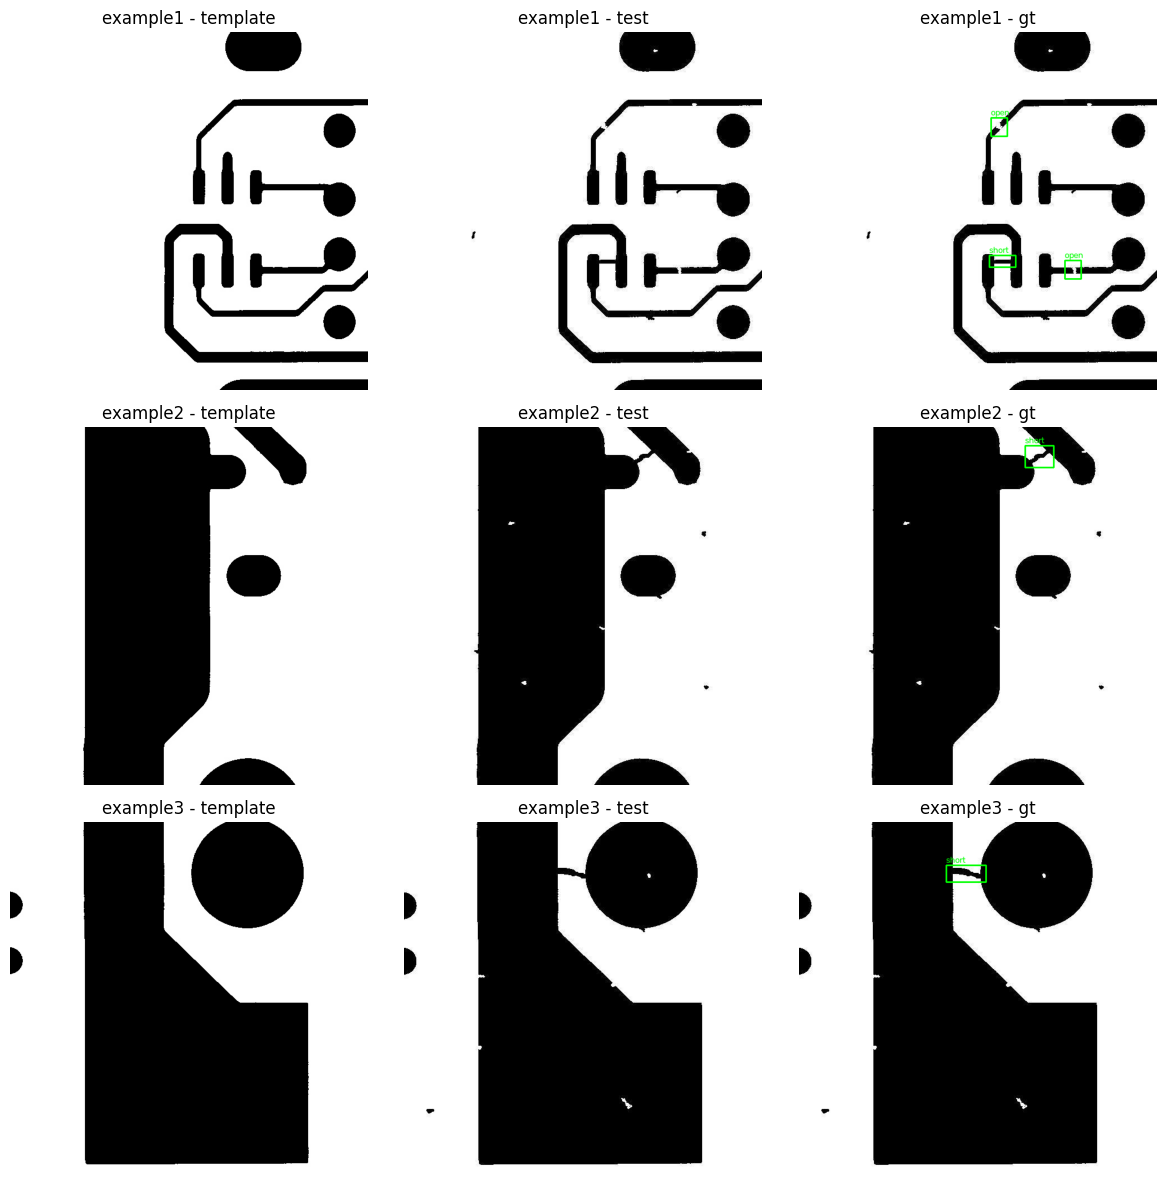

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    for j, kind in enumerate(["template", "test", "gt"]):
        img = cv2.imread(f"examples/example{i + 1}_{kind}.png")
        axes[i][j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i][j].set_title(f"example{i + 1} - {kind}")
        axes[i][j].axis("off")
plt.tight_layout()
plt.show()